# Clasificación: Regresión Logística

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from Modelado import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_CLF, ESTRATEGIAS,
    cargar_split, separar_x_y, crear_cv, dispositivo_modelo, coeficientes_logistica, verificar_smotenc,
    ejecutar_fase1, formatear_tabla_cv, graficar_estrategias, elegir_mejor, guardar_fase1,
    formatear_hiperparametros,
)

CLAVE = "logistica"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_modelo(CLAVE),
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,Logística
USAR_GPU,True
GPU detectada por librería,"xgboost: cuda, catboost: GPU, lightgbm: cuda"
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y(df_train)
cv = crear_cv(SEED)

pd.DataFrame({
    "Filas": [len(X_train)],
    "Predictores": [X_train.shape[1]],
    "Deprimidos": [int(y_train.sum())],
    "Prevalencia": [round(y_train.mean(), 3)],
}, index=pd.Index(["Train"], name="Conjunto"))

,Filas,Predictores,Deprimidos,Prevalencia
Conjunto,,,,
Train,3848,6,630,0.164


### Estrategias de Manejo del Desbalance

Se comparan las tres estrategias de [manejo del desbalance](#mod-desbalance). En la logística, los pesos de clase se aplican con `class_weight="balanced"` (equivale a la logística benchmark).

In [4]:
tabla_clases, tabla_sexo = verificar_smotenc(X_train, y_train, seed=SEED)
display(tabla_clases)
display(tabla_sexo)

✓ sex solo toma los valores ['Boy', 'Girl']
✓ Clases balanceadas: {0: 3218, 1: 3218}


,Antes,Después,Sintéticos
Deprimido,,,
0,3218,3218,0
1,630,3218,2588


Deprimido,0,1
Sexo,,
Boy,1789,770
Girl,1429,2448


### Validación Cruzada por Estrategia

La logística no tiene hiperparámetros que ajustar (`LogisticRegression(max_iter=1000)`, con la regularización por defecto), así que cada estrategia se evalúa directamente con `cross_validate` **solo sobre el train**, con los mismos folds y las mismas métricas que los demás modelos.

In [5]:
tabla, pipelines, hiperparametros = ejecutar_fase1(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo (sin balanceo)  PR-AUC = 0.3925 ± 0.0423  (2 s)
✓ Pesos de clase         PR-AUC = 0.3930 ± 0.0431  (2 s)
✓ SMOTENC                PR-AUC = 0.3920 ± 0.0417  (2 s)


In [6]:
vista = formatear_tabla_cv(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(1)
vista.rename(index=ESTRATEGIAS)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Tiempo (s)
Estrategia,,,,,,,
Nativo (sin balanceo),0.393 ± 0.042,0.755 ± 0.030,0.564 ± 0.042,0.122 ± 0.025,0.199 ± 0.034,0.840 ± 0.003,2.3
Pesos de clase,0.393 ± 0.043,0.756 ± 0.030,0.309 ± 0.032,0.652 ± 0.053,0.420 ± 0.040,0.704 ± 0.026,1.7
SMOTENC,0.392 ± 0.042,0.754 ± 0.029,0.308 ± 0.024,0.654 ± 0.056,0.418 ± 0.033,0.702 ± 0.016,1.6


Las tres estrategias obtienen prácticamente la misma PR-AUC (0.393, 0.393 y 0.392, con desviaciones de 0.042 a 0.043 que se solapan por completo) y la misma ROC-AUC (0.755 ± 0.030, 0.756 ± 0.030 y 0.754 ± 0.029). La capacidad discriminativa existe, pero es modesta.

Las diferencias aparecen en las demás métricas, calculadas con el umbral de 0.5. El nativo tiene la precision más alta (0.564 ± 0.042), pero su recall de 0.122 ± 0.025 implica que se le escapa casi el 90% de los casos, lo que deja el F1 en 0.199 ± 0.034. Su accuracy de 0.840 ± 0.003 es la más alta, pero apenas supera la de predecir siempre “no deprimido” (1 − 0.164 = 0.836), así que no refleja capacidad predictiva.

Los pesos de clase y SMOTENC se comportan casi igual: recall de 0.652 ± 0.053 y 0.654 ± 0.056, precision de 0.309 ± 0.032 y 0.308 ± 0.024, y F1 de 0.420 ± 0.040 y 0.418 ± 0.033. Su accuracy baja a 0.704 ± 0.026 y 0.702 ± 0.016 por el aumento de falsos positivos en la clase mayoritaria.

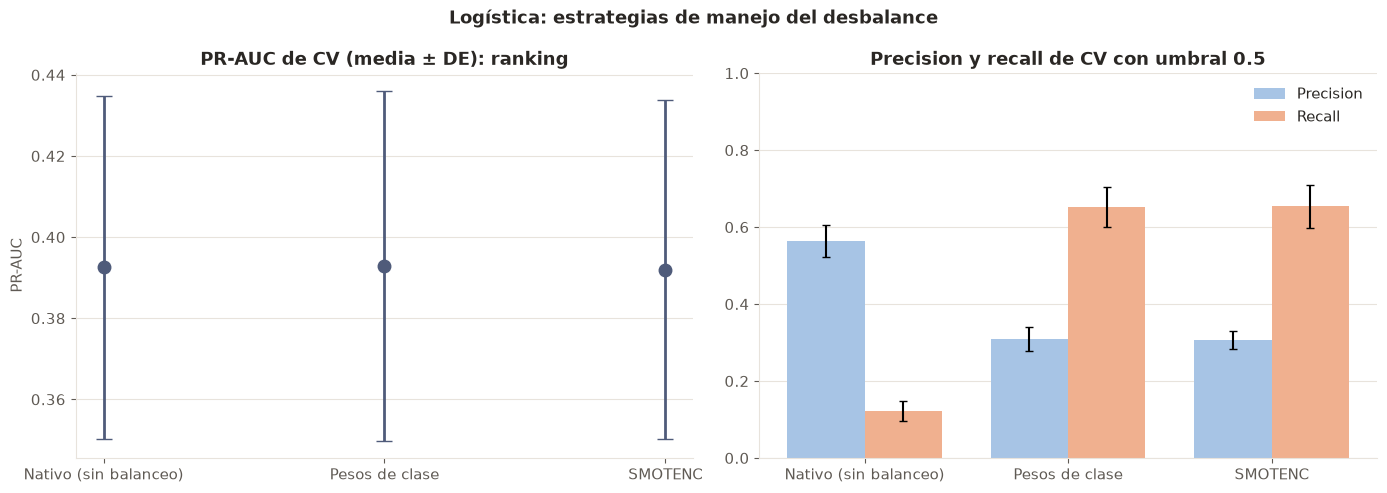

In [7]:
fig = graficar_estrategias(tabla, NOMBRES_CLF[CLAVE])
plt.show()

La gráfica confirma que las tres estrategias producen esencialmente el mismo modelo. La PR-AUC media es prácticamente idéntica (~0.39) y las barras de desviación se solapan por completo, así que ni los pesos de clase ni SMOTENC mejoran la capacidad de la logística para ordenar los positivos por encima de los negativos. Lo que cambia es el punto de operación con el umbral fijo de 0.5: el nativo casi no predice la clase minoritaria (precision ~0.56, recall ~0.12), mientras que los pesos de clase y SMOTENC desplazan las probabilidades hacia la clase positiva y llevan el recall a ~0.65 a costa de una precision de ~0.31.

**Coeficientes por estrategia** (variables estandarizadas)

In [8]:
pd.DataFrame({
    ESTRATEGIAS[estrategia]: coeficientes_logistica(pipeline).set_index("Variable")["Coeficiente"]
    for estrategia, pipeline in pipelines.items()
}).round(3)

,Nativo (sin balanceo),Pesos de clase,SMOTENC
Variable,,,
sleep_quality_index,0.526,0.572,0.701
avg_sleep_hours,-0.179,-0.181,-0.188
midsleep_weekend_hours,0.209,0.242,0.198
social_jetlag_hours,-0.054,-0.076,-0.004
screen_time_index,0.064,0.094,0.089
sex_Girl,1.064,1.091,1.160


Los coeficientes son estables en signo y orden de magnitud entre estrategias. Ser mujer (`sex_Girl`, 1.06 a 1.16) es el predictor con mayor coeficiente, seguido de `sleep_quality_index` (0.53 a 0.70); más horas de sueño reducen el riesgo (`avg_sleep_hours`, ≈ −0.18), y un punto medio de sueño más tardío el fin de semana (`midsleep_weekend_hours`, 0.20 a 0.24) y el tiempo de pantalla (`screen_time_index`, 0.06 a 0.09) lo aumentan levemente. El *social jetlag* tiene un coeficiente cercano a cero (−0.08 a 0.00). El coeficiente de `sex_Girl` no es directamente comparable con los demás, porque es una variable dummy (0/1) y no está estandarizada.

SMOTENC es la estrategia que más altera los coeficientes: refuerza `sleep_quality_index` (0.70) y lleva el *social jetlag* prácticamente a cero (−0.004).

### Selección del Mejor Modelo Regresión Logística

In [9]:
estrategia_ganadora, explicacion = elegir_mejor(tabla)

pd.Series({
    "Estrategia ganadora": ESTRATEGIAS[estrategia_ganadora],
    "PR-AUC de CV": f"{tabla.loc[estrategia_ganadora, 'PR-AUC media']:.4f} ± {tabla.loc[estrategia_ganadora, 'PR-AUC DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[estrategia_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,Logística
Estrategia ganadora,Pesos de clase
PR-AUC de CV,0.3930 ± 0.0431
Hiperparámetros,sin tuning
Criterio,Se elige 'pesos': tiene la mayor PR-AUC media de CV (0.3930 ± 0.0431).


Se eligen los pesos de clase, que tienen la PR-AUC media más alta (0.3930 ± 0.0431). Su ventaja sobre el nativo (0.0005) y SMOTENC (0.0010) es mucho menor que la desviación entre folds, así que en la práctica las tres estrategias son equivalentes. Con pesos de clase, este modelo es el mismo que la logística benchmark (`class_weight="balanced"`).

### Guardado

In [10]:
ganador = guardar_fase1(
    CLAVE, tabla, estrategia_ganadora, pipelines[estrategia_ganadora],
    hiperparametros[estrategia_ganadora], explicacion,
)